## Deep Q-Network (DQN) — Entraînement de l'agent ATC

### Architecture globale

Le DQN combine :
- **Q-Network** (réseau principal) : MLP 6→128→128→5, prédit Q(s,a) pour tout état s
- **Target Network** : copie "gelée" du Q-Network, mise à jour toutes les C étapes (stabilité)
- **Experience Replay Buffer** : stocke les transitions (s, a, r, s', done) pour briser les corrélations temporelles
- **Politique ε-greedy** : exploration décroissante de ε=1.0 → ε=0.05

### Hyperparamètres clés
| Paramètre | Valeur | Rôle |
|---|---|---|
| γ (gamma) | 0.99 | Facteur d'actualisation |
| ε initial | 1.0 | Exploration maximale |
| ε final | 0.05 | Exploitation quasi-totale |
| ε décroissance | 0.995/épisode | Vitesse de passage exploit→explore |
| Taille buffer | 10 000 | Transitions mémorisées |
| Batch size | 64 | Transitions par mise à jour |
| LR (Adam) | 1e-3 | Vitesse d'apprentissage |
| Mise à jour target | toutes 10 ép. | Fréquence de sync Target ← Online |
| Épisodes total | 1 000 | Budget d'entraînement |

In [1]:
import torch
import torch.nn as nn
import torch.optim as optim
import numpy as np
import random
import warnings
from collections import deque
import matplotlib.pyplot as plt

warnings.filterwarnings('ignore')

# Chargement du tenseur d'états initiaux
initial_states_tensor = torch.load("initial_states.pt", weights_only=True)
print(f"Tenseur chargé. Shape : {initial_states_tensor.shape}")

# Dispositif de calcul (GPU si disponible, sinon CPU)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Dispositif utilisé : {device}")

Tenseur chargé. Shape : torch.Size([43, 6])
Dispositif utilisé : cpu


## Définition de l'environnement ATCEnv v2

Copie de l'environnement défini dans `ATC_Reinforcement_Learning.ipynb` pour que ce notebook soit autonome.

In [2]:
import gymnasium as gym
from gymnasium import spaces
import numpy as np

class ATCEnv(gym.Env):
    metadata = {"render_modes": []}
    COLLISION_HORIZ = 0.15
    COLLISION_VERT  = 0.15
    SAFE_HORIZ      = 2.0
    SAFE_VERT       = 1.0
    
    def __init__(self, initial_states_tensor, max_steps=60, dt=10.0):
        super(ATCEnv, self).__init__()
        self.initial_states = initial_states_tensor.numpy()
        self.max_steps = max_steps
        self.dt = dt
        self.action_space = spaces.Discrete(5)
        self.observation_space = spaces.Box(low=-10.0, high=10.0, shape=(6,), dtype=np.float32)
        self.state = None
        self.current_step = 0
        self.prev_dist_horiz = 0.0
        self.prev_dist_vert  = 0.0

    def reset(self, seed=None, options=None):
        super().reset(seed=seed)
        idx = self.np_random.integers(len(self.initial_states))
        self.state = self.initial_states[idx].copy().astype(np.float32)
        self.current_step = 0
        dx, dy, dz, _, _, _ = self.state
        self.prev_dist_horiz = float(np.hypot(dx, dy))
        self.prev_dist_vert  = float(abs(dz))
        return self.state, {}

    def step(self, action):
        dx, dy, dz, dvx, dvy, dvz = self.state
        if action == 1:
            theta = np.radians(15.0)
            dvx, dvy = (dvx * np.cos(theta) - dvy * np.sin(theta),
                        dvx * np.sin(theta) + dvy * np.cos(theta))
        elif action == 2:
            theta = np.radians(-15.0)
            dvx, dvy = (dvx * np.cos(theta) - dvy * np.sin(theta),
                        dvx * np.sin(theta) + dvy * np.cos(theta))
        elif action == 3:
            dvz += 0.1
        elif action == 4:
            dvz -= 0.1
        scale = self.dt / 60.0
        dx += dvx * scale
        dy += dvy * scale
        dz += dvz * scale
        self.state = np.array([dx, dy, dz, dvx, dvy, dvz], dtype=np.float32)
        curr_dist_horiz = float(np.hypot(dx, dy))
        curr_dist_vert  = float(abs(dz))
        reward = 0.0
        terminated = False
        collision = False
        success = False
        if curr_dist_horiz < self.COLLISION_HORIZ and curr_dist_vert < self.COLLISION_VERT:
            reward -= 50.0
            terminated = True
            collision = True
        elif curr_dist_horiz >= self.SAFE_HORIZ and curr_dist_vert >= self.SAFE_VERT:
            reward += 100.0
            terminated = True
            success = True
        else:
            delta_horiz = curr_dist_horiz - self.prev_dist_horiz
            reward += delta_horiz * 5.0
            delta_vert = curr_dist_vert - self.prev_dist_vert
            reward += delta_vert * 2.0
            if curr_dist_horiz > 1.5:
                reward += 0.5
        reward -= 0.05
        if action != 0:
            reward -= 0.02
        self.prev_dist_horiz = curr_dist_horiz
        self.prev_dist_vert  = curr_dist_vert
        self.current_step += 1
        truncated = self.current_step >= self.max_steps
        info = {"collision": collision, "success": success,
                "dist_horiz": curr_dist_horiz, "dist_vert": curr_dist_vert}
        return self.state, reward, terminated, truncated, info

# Vérification rapide de l'environnement
env_test = ATCEnv(initial_states_tensor)
obs, _ = env_test.reset(seed=0)
print(f"ATCEnv v2 OK — observation shape: {obs.shape}, action space: {env_test.action_space.n}")

ATCEnv v2 OK — observation shape: (6,), action space: 5


## 1. Q-Network (MLP PyTorch)

Réseau de neurones qui approxime la fonction de valeur Q(s, a).
- **Entrée** : état s de dimension 6 → `[dx, dy, dz, dvx, dvy, dvz]`
- **Sorties** : 5 Q-values, une par action possible
- **Architecture** : 6 → 128 → 128 → 5, activations ReLU entre les couches cachées

In [3]:
class QNetwork(nn.Module):
    """
    Réseau MLP approximant Q(s, a) pour l'environnement ATC.
    Entrée  : état normalisé de dimension state_dim (6)
    Sortie  : Q-values pour chaque action (action_dim = 5)
    """
    def __init__(self, state_dim: int = 6, action_dim: int = 5, hidden: int = 128):
        super(QNetwork, self).__init__()
        self.net = nn.Sequential(
            nn.Linear(state_dim, hidden),
            nn.ReLU(),
            nn.Linear(hidden, hidden),
            nn.ReLU(),
            nn.Linear(hidden, action_dim)
        )
    
    def forward(self, x: torch.Tensor) -> torch.Tensor:
        return self.net(x)

# Test rapide
_net = QNetwork()
_dummy = torch.zeros(1, 6)
_out = _net(_dummy)
print(f"QNetwork OK — output shape: {_out.shape}")  # → torch.Size([1, 5])
print(f"Nombre de paramètres : {sum(p.numel() for p in _net.parameters()):,}")

QNetwork OK — output shape: torch.Size([1, 5])
Nombre de paramètres : 18,053


## 2. Experience Replay Buffer

Stocke les transitions `(state, action, reward, next_state, done)` dans une file circulaire (deque).  
À chaque étape d'apprentissage, on tire un **mini-batch aléatoire** de 64 transitions pour briser les corrélations temporelles et stabiliser l'entraînement.

In [4]:
class ReplayBuffer:
    """
    Buffer de replay circulaire de capacité maximale `capacity`.
    Stocke des transitions (state, action, reward, next_state, done).
    """
    def __init__(self, capacity: int = 10_000):
        self.buffer = deque(maxlen=capacity)
    
    def push(self, state, action, reward, next_state, done):
        """Ajoute une transition au buffer."""
        self.buffer.append((
            np.array(state,      dtype=np.float32),
            int(action),
            float(reward),
            np.array(next_state, dtype=np.float32),
            bool(done)
        ))
    
    def sample(self, batch_size: int):
        """Tire un batch aléatoire de transitions."""
        batch = random.sample(self.buffer, batch_size)
        states, actions, rewards, next_states, dones = zip(*batch)
        return (
            torch.tensor(np.array(states),      dtype=torch.float32),
            torch.tensor(np.array(actions),     dtype=torch.long),
            torch.tensor(np.array(rewards),     dtype=torch.float32),
            torch.tensor(np.array(next_states), dtype=torch.float32),
            torch.tensor(np.array(dones),       dtype=torch.float32),
        )
    
    def __len__(self):
        return len(self.buffer)

print("ReplayBuffer OK")

ReplayBuffer OK


## 3. Agent DQN

L'agent encapsule :
- Le **Q-Network** (réseau d'apprentissage, mis à jour à chaque étape)
- Le **Target Network** (copie stable, synchronisée toutes les `target_update` époques)
- La **politique ε-greedy** pour l'exploration
- La **mise à jour par descente de gradient** sur la loss de Bellman (Huber Loss)

### Équation de Bellman (objectif d'entraînement)

$$Q(s, a) \leftarrow r + \gamma \cdot \max_{a'} Q_{\text{target}}(s', a') \cdot (1 - \text{done})$$

La **Huber Loss** (moins sensible aux grandes erreurs que MSE) est utilisée entre la Q-value prédite et la cible de Bellman.

In [5]:
class DQNAgent:
    """
    Agent Deep Q-Network pour la résolution de conflits ATC.
    
    Paramètres
    ----------
    state_dim    : dimension de l'espace d'observation (6)
    action_dim   : nombre d'actions (5)
    lr           : taux d'apprentissage Adam
    gamma        : facteur d'actualisation
    epsilon      : taux d'exploration initial
    epsilon_min  : taux d'exploration minimal
    epsilon_decay: facteur multiplicatif de décroissance d'epsilon par épisode
    buffer_size  : capacité du replay buffer
    batch_size   : taille du mini-batch d'apprentissage
    target_update: fréquence de synchronisation du target network (en épisodes)
    """
    
    def __init__(
        self,
        state_dim:     int   = 6,
        action_dim:    int   = 5,
        lr:            float = 1e-3,
        gamma:         float = 0.99,
        epsilon:       float = 1.0,
        epsilon_min:   float = 0.05,
        epsilon_decay: float = 0.995,
        buffer_size:   int   = 10_000,
        batch_size:    int   = 64,
        target_update: int   = 10,
    ):
        self.action_dim    = action_dim
        self.gamma         = gamma
        self.epsilon       = epsilon
        self.epsilon_min   = epsilon_min
        self.epsilon_decay = epsilon_decay
        self.batch_size    = batch_size
        self.target_update = target_update
        self.episode_count = 0
        
        # Réseaux de neurones
        self.q_network     = QNetwork(state_dim, action_dim).to(device)
        self.target_network = QNetwork(state_dim, action_dim).to(device)
        self.target_network.load_state_dict(self.q_network.state_dict())
        self.target_network.eval()  # Target network toujours en mode inférence
        
        # Optimiseur et fonction de perte
        self.optimizer = optim.Adam(self.q_network.parameters(), lr=lr)
        self.loss_fn   = nn.HuberLoss()
        
        # Buffer de replay
        self.replay_buffer = ReplayBuffer(capacity=buffer_size)
    
    # ------------------------------------------------------------------
    def select_action(self, state: np.ndarray) -> int:
        """Choisit une action selon la politique ε-greedy."""
        if random.random() < self.epsilon:
            return random.randint(0, self.action_dim - 1)  # Exploration aléatoire
        
        state_tensor = torch.tensor(state, dtype=torch.float32).unsqueeze(0).to(device)
        with torch.no_grad():
            q_values = self.q_network(state_tensor)
        return int(q_values.argmax(dim=1).item())  # Exploitation
    
    # ------------------------------------------------------------------
    def learn(self):
        """Effectue une mise à jour du Q-Network sur un batch aléatoire."""
        if len(self.replay_buffer) < self.batch_size:
            return None  # Pas assez de données
        
        states, actions, rewards, next_states, dones = self.replay_buffer.sample(self.batch_size)
        states      = states.to(device)
        actions     = actions.to(device)
        rewards     = rewards.to(device)
        next_states = next_states.to(device)
        dones       = dones.to(device)
        
        # Q-values prédites par le réseau principal pour les actions effectuées
        q_pred = self.q_network(states).gather(1, actions.unsqueeze(1)).squeeze(1)
        
        # Cibles de Bellman via le Target Network
        with torch.no_grad():
            q_next  = self.target_network(next_states).max(dim=1)[0]
            q_target = rewards + self.gamma * q_next * (1.0 - dones)
        
        # Calcul et rétropropagation de la Huber Loss
        loss = self.loss_fn(q_pred, q_target)
        self.optimizer.zero_grad()
        loss.backward()
        # Gradient clipping pour éviter les explosions de gradient
        nn.utils.clip_grad_norm_(self.q_network.parameters(), max_norm=10.0)
        self.optimizer.step()
        
        return loss.item()
    
    # ------------------------------------------------------------------
    def update_epsilon(self):
        """Décroissance de ε après chaque épisode."""
        self.epsilon = max(self.epsilon_min, self.epsilon * self.epsilon_decay)
    
    # ------------------------------------------------------------------
    def sync_target_network(self):
        """Copie les poids du Q-Network vers le Target Network."""
        self.target_network.load_state_dict(self.q_network.state_dict())

print("DQNAgent OK")

DQNAgent OK


## 4. Boucle d'entraînement

Algorithme DQN standard :
1. Pour chaque épisode, réinitialiser l'environnement
2. À chaque pas : choisir une action (ε-greedy) → exécuter → stocker la transition
3. Après chaque pas : apprendre sur un batch aléatoire du replay buffer
4. Après chaque épisode : décroître ε, synchroniser le Target Network toutes les `target_update` épisodes
5. Logger les métriques (récompense, epsilon, taux de succès) toutes les 50 épisodes

In [10]:
# === HYPERPARAMÈTRES ===
N_EPISODES    = 1_000
TARGET_UPDATE = 10     # Sync target network toutes les 10 épisodes
LOG_EVERY     = 50     # Afficher les stats toutes les 50 épisodes

# === INITIALISATION ===
env   = ATCEnv(initial_states_tensor)
agent = DQNAgent(
    state_dim=6, action_dim=5,
    lr=1e-3, gamma=0.99,
    epsilon=1.0, epsilon_min=0.05, epsilon_decay=0.995,
    buffer_size=10_000, batch_size=64,
    target_update=TARGET_UPDATE
)

# Suivi des métriques
all_rewards   = []
all_losses    = []
all_epsilons  = []
success_flags = []
collision_flags = []

print("=" * 60)
print("   Entraînement DQN — ATCEnv v2")
print("=" * 60)
print(f"{'Épisode':>8} | {'Reward moy':>10} | {'ε':>6} | {'Succès':>7} | {'Collis.':>7}")
print("-" * 60)

for episode in range(1, N_EPISODES + 1):
    obs, _ = env.reset()
    total_reward = 0.0
    episode_losses = []
    done = False
    
    while not done:
        # 1. Choisir une action
        action = agent.select_action(obs)
        
        # 2. Interagir avec l'environnement
        next_obs, reward, terminated, truncated, info = env.step(action)
        done = terminated or truncated
        
        # 3. Stocker la transition dans le buffer
        agent.replay_buffer.push(obs, action, reward, next_obs, float(done))
        
        # 4. Apprendre
        loss = agent.learn()
        if loss is not None:
            episode_losses.append(loss)
        
        obs = next_obs
        total_reward += reward
    
    # 5. Fin d'épisode : mise à jour epsilon et target network
    agent.update_epsilon()
    if episode % TARGET_UPDATE == 0:
        agent.sync_target_network()
    
    # Enregistrement des métriques
    all_rewards.append(total_reward)
    all_epsilons.append(agent.epsilon)
    success_flags.append(info.get("success", False))
    collision_flags.append(info.get("collision", False))
    if episode_losses:
        all_losses.append(np.mean(episode_losses))
    
    # Affichage périodique
    if episode % LOG_EVERY == 0:
        window = min(LOG_EVERY, len(all_rewards))
        mean_r   = np.mean(all_rewards[-window:])
        success_r = np.mean(success_flags[-window:]) * 100
        collis_r  = np.mean(collision_flags[-window:]) * 100
        print(f"{episode:>8} | {mean_r:>+10.2f} | {agent.epsilon:>6.3f} | {success_r:>6.1f}% | {collis_r:>6.1f}%")

print("-" * 60)
print("Entraînement terminé !")

   Entraînement DQN — ATCEnv v2
 Épisode | Reward moy |      ε |  Succès | Collis.
------------------------------------------------------------
      50 |     +86.12 |  0.778 |   80.0% |   16.0%
     100 |     +96.65 |  0.606 |   80.0% |    8.0%
     150 |     +72.18 |  0.471 |   74.0% |   26.0%
     200 |    +106.19 |  0.367 |   92.0% |    4.0%
     250 |     +90.14 |  0.286 |   82.0% |   16.0%
     300 |    +102.02 |  0.222 |   94.0% |    6.0%
     350 |    +105.00 |  0.173 |   92.0% |    8.0%
     400 |    +107.83 |  0.135 |   96.0% |    4.0%
     450 |     +96.87 |  0.105 |   88.0% |   12.0%
     500 |    +108.48 |  0.082 |   96.0% |    4.0%
     550 |    +109.88 |  0.063 |   96.0% |    4.0%
     600 |    +109.65 |  0.050 |   96.0% |    4.0%
     650 |     +87.85 |  0.050 |   82.0% |   18.0%
     700 |     +96.38 |  0.050 |   86.0% |   12.0%
     750 |    +104.43 |  0.050 |   88.0% |   10.0%
     800 |     +84.81 |  0.050 |   80.0% |   20.0%
     850 |    +103.11 |  0.050 |   90.0%

## 5. Visualisation des résultats d'entraînement

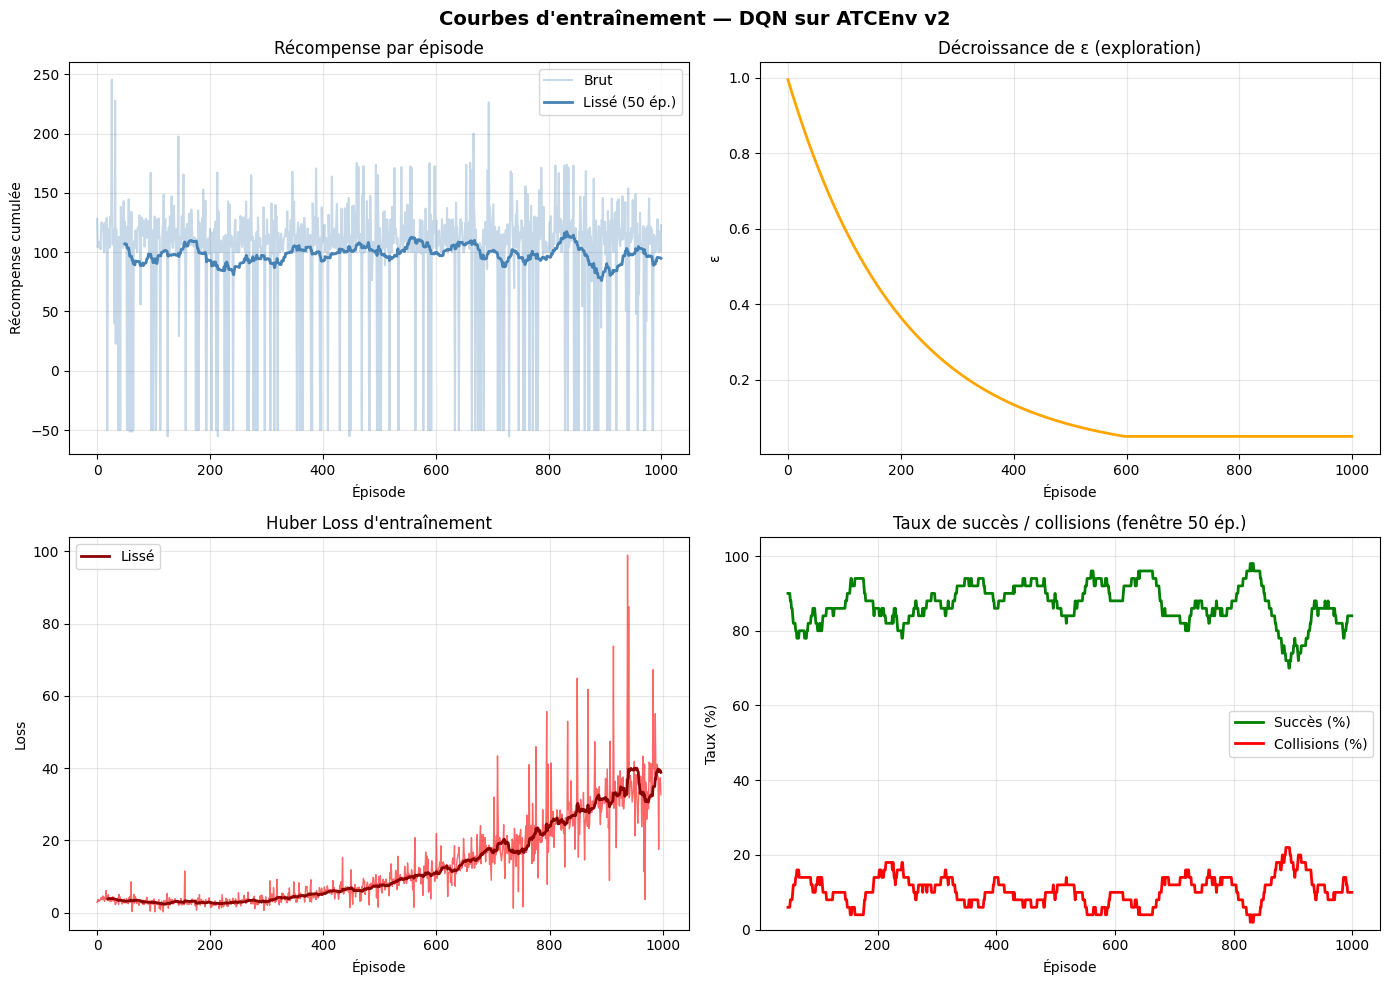

Graphique sauvegardé → training_curves.png


In [7]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
fig.suptitle("Courbes d'entraînement — DQN sur ATCEnv v2", fontsize=14, fontweight='bold')

# --- Récompense par épisode (lissée) ---
ax = axes[0, 0]
window_size = 50
smoothed_rewards = np.convolve(all_rewards, np.ones(window_size)/window_size, mode='valid')
ax.plot(all_rewards, alpha=0.3, color='steelblue', label='Brut')
ax.plot(range(window_size-1, len(all_rewards)), smoothed_rewards, color='steelblue', linewidth=2, label=f'Lissé ({window_size} ép.)')
ax.set_title("Récompense par épisode")
ax.set_xlabel("Épisode")
ax.set_ylabel("Récompense cumulée")
ax.legend()
ax.grid(True, alpha=0.3)

# --- Décroissance de epsilon ---
ax = axes[0, 1]
ax.plot(all_epsilons, color='orange', linewidth=2)
ax.set_title("Décroissance de ε (exploration)")
ax.set_xlabel("Épisode")
ax.set_ylabel("ε")
ax.grid(True, alpha=0.3)

# --- Loss d'entraînement ---
ax = axes[1, 0]
if all_losses:
    ax.plot(all_losses, alpha=0.6, color='red', linewidth=1)
    loss_smooth = np.convolve(all_losses, np.ones(20)/20, mode='valid')
    ax.plot(range(19, len(all_losses)), loss_smooth, color='darkred', linewidth=2, label='Lissé')
    ax.set_title("Huber Loss d'entraînement")
    ax.set_xlabel("Épisode")
    ax.set_ylabel("Loss")
    ax.legend()
    ax.grid(True, alpha=0.3)

# --- Taux de succès et de collisions (fenêtre glissante) ---
ax = axes[1, 1]
window_size = 50
success_rate = np.convolve([float(s) for s in success_flags], np.ones(window_size)/window_size, mode='valid') * 100
collision_rate = np.convolve([float(c) for c in collision_flags], np.ones(window_size)/window_size, mode='valid') * 100
x_range = range(window_size-1, len(success_flags))
ax.plot(x_range, success_rate,   color='green', linewidth=2, label='Succès (%)')
ax.plot(x_range, collision_rate, color='red',   linewidth=2, label='Collisions (%)')
ax.set_title(f"Taux de succès / collisions (fenêtre {window_size} ép.)")
ax.set_xlabel("Épisode")
ax.set_ylabel("Taux (%)")
ax.legend()
ax.grid(True, alpha=0.3)
ax.set_ylim(0, 105)

plt.tight_layout()
plt.savefig("training_curves.png", dpi=150, bbox_inches='tight')
plt.show()
print("Graphique sauvegardé → training_curves.png")

## 6. Évaluation finale — Agent DQN vs Agent aléatoire

Comparaison sur 200 épisodes :
- **Agent DQN** : politique greedy (ε=0, toujours la meilleure action connue)  
- **Agent aléatoire** : actions uniformément aléatoires (baseline)


  Agent DQN (greedy) — 200 épisodes
  Récompense moyenne  : +93.64 ± 60.79
  Récompense max/min  : 163.62 / -51.33
  Taux de succès      : 85.5%
  Taux de collisions  : 14.5%

  Agent Aléatoire — 200 épisodes
  Récompense moyenne  : +85.98 ± 62.01
  Récompense max/min  : 194.85 / -57.82
  Taux de succès      : 78.5%
  Taux de collisions  : 15.0%


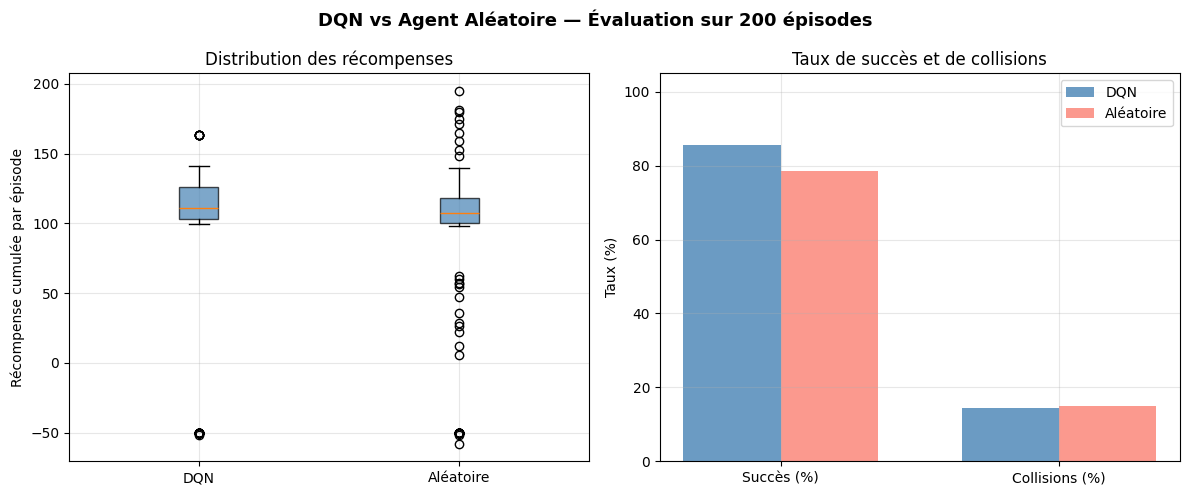

Graphique sauvegardé → evaluation_comparison.png


In [8]:
def evaluate_agent(env, agent_fn, n_episodes=200, label="Agent"):
    """Évalue un agent sur n épisodes et retourne les statistiques."""
    rewards   = []
    successes = []
    collisions = []
    
    for ep in range(n_episodes):
        obs, _ = env.reset(seed=ep)
        total_reward = 0.0
        done = False
        while not done:
            action = agent_fn(obs)
            obs, reward, terminated, truncated, info = env.step(action)
            total_reward += reward
            done = terminated or truncated
        rewards.append(total_reward)
        successes.append(info.get("success", False))
        collisions.append(info.get("collision", False))
    
    print(f"\n{'='*50}")
    print(f"  {label} — {n_episodes} épisodes")
    print(f"{'='*50}")
    print(f"  Récompense moyenne  : {np.mean(rewards):+.2f} ± {np.std(rewards):.2f}")
    print(f"  Récompense max/min  : {max(rewards):.2f} / {min(rewards):.2f}")
    print(f"  Taux de succès      : {np.mean(successes)*100:.1f}%")
    print(f"  Taux de collisions  : {np.mean(collisions)*100:.1f}%")
    return rewards, successes, collisions

eval_env = ATCEnv(initial_states_tensor)

# --- Agent DQN (greedy, epsilon=0) ---
def dqn_policy(obs):
    state_tensor = torch.tensor(obs, dtype=torch.float32).unsqueeze(0).to(device)
    with torch.no_grad():
        q_values = agent.q_network(state_tensor)
    return int(q_values.argmax(dim=1).item())

# --- Agent aléatoire ---
def random_policy(obs):
    return eval_env.action_space.sample()

dqn_rewards, dqn_successes, dqn_collisions = evaluate_agent(
    eval_env, dqn_policy, n_episodes=200, label="Agent DQN (greedy)"
)
rand_rewards, rand_successes, rand_collisions = evaluate_agent(
    eval_env, random_policy, n_episodes=200, label="Agent Aléatoire"
)

# --- Boxplot comparatif ---
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))
fig.suptitle("DQN vs Agent Aléatoire — Évaluation sur 200 épisodes", fontsize=13, fontweight='bold')

ax1.boxplot([dqn_rewards, rand_rewards], labels=["DQN", "Aléatoire"], patch_artist=True,
            boxprops=dict(facecolor='steelblue', alpha=0.7))
ax1.set_title("Distribution des récompenses")
ax1.set_ylabel("Récompense cumulée par épisode")
ax1.grid(True, alpha=0.3)

categories = ['Succès (%)', 'Collisions (%)']
dqn_rates  = [np.mean(dqn_successes)*100,   np.mean(dqn_collisions)*100]
rand_rates = [np.mean(rand_successes)*100, np.mean(rand_collisions)*100]
x = np.arange(len(categories))
width = 0.35
ax2.bar(x - width/2, dqn_rates,  width, label='DQN',       color='steelblue', alpha=0.8)
ax2.bar(x + width/2, rand_rates, width, label='Aléatoire', color='salmon',    alpha=0.8)
ax2.set_xticks(x)
ax2.set_xticklabels(categories)
ax2.set_title("Taux de succès et de collisions")
ax2.set_ylabel("Taux (%)")
ax2.legend()
ax2.grid(True, alpha=0.3)
ax2.set_ylim(0, 105)

plt.tight_layout()
plt.savefig("evaluation_comparison.png", dpi=150, bbox_inches='tight')
plt.show()
print("Graphique sauvegardé → evaluation_comparison.png")

## 7. Sauvegarde du modèle entraîné

In [9]:
# Sauvegarde du Q-Network entraîné
MODEL_PATH = "dqn_atc_model.pt"
torch.save({
    'q_network_state_dict': agent.q_network.state_dict(),
    'optimizer_state_dict': agent.optimizer.state_dict(),
    'epsilon': agent.epsilon,
    'episode': N_EPISODES,
    'hyperparams': {
        'state_dim': 6, 'action_dim': 5,
        'gamma': 0.99, 'lr': 1e-3,
        'epsilon_min': 0.05, 'epsilon_decay': 0.995,
        'buffer_size': 10_000, 'batch_size': 64,
        'target_update': TARGET_UPDATE,
    }
}, MODEL_PATH)
print(f"Modèle DQN sauvegardé → {MODEL_PATH}")

# Chargement du modèle (exemple de rechargement)
checkpoint = torch.load(MODEL_PATH, weights_only=True)
loaded_net = QNetwork(state_dim=6, action_dim=5).to(device)
loaded_net.load_state_dict(checkpoint['q_network_state_dict'])
loaded_net.eval()
print(f"Modèle rechargé avec succès. Epsilon final : {checkpoint['epsilon']:.4f}")

Modèle DQN sauvegardé → dqn_atc_model.pt
Modèle rechargé avec succès. Epsilon final : 0.0500
